# 1. DATA COLLECTING

Dataset diambil dari Kaggle (*Spotify Tracks Dataset - Updated Every Week*). Data diekstrak dari Spotify Web API dan berisi lagu dari berbagai bahasa. Pada laporan ini hanya lagu berbahasa **Korea** yang dipakai.

Keterangan kolom:
- `popularity` : tingkat popularitas lagu (0-100) -> **target**
- `year` : tahun rilis, `artist_name` : nama artis
- `acousticness`, `danceability`, `energy`, `instrumentalness`, `liveness`, `speechiness`, `valence` : fitur audio (0-1)
- `loudness` : kenyaringan (dB), `tempo` : kecepatan (BPM), `duration_ms` : durasi (ms)
- `key`, `mode`, `time_signature` : informasi musikal

# 2. DATA LOADING

In [41]:
import pandas as pd

data = pd.read_csv("spotify_tracks.csv")
print("Ukuran seluruh dataset:", data.shape)
data.head()

Ukuran seluruh dataset: (62317, 22)


,track_id,track_name,artist_name,year,popularity,artwork_url,album_name,acousticness,danceability,duration_ms,...,key,liveness,loudness,mode,speechiness,tempo,time_signature,valence,track_url,language
0,2r0ROhr7pRN4MXDMT1fEmd,"Leo Das Entry (From ""Leo"")",Anirudh Ravichander,2024,59,https://i.scdn.co/image/ab67616d0000b273ce9c65...,"Leo Das Entry (From ""Leo"")",0.0241,0.753,97297.0,...,8.0,0.1000,-5.994,0.0,0.1030,110.997,4.0,0.459,https://open.spotify.com/track/2r0ROhr7pRN4MXD...,Tamil
1,4I38e6Dg52a2o2a8i5Q5PW,AAO KILLELLE,"Anirudh Ravichander, Pravin Mani, Vaishali Sri...",2024,47,https://i.scdn.co/image/ab67616d0000b273be1b03...,AAO KILLELLE,0.0851,0.780,207369.0,...,10.0,0.0951,-5.674,0.0,0.0952,164.995,3.0,0.821,https://open.spotify.com/track/4I38e6Dg52a2o2a...,Tamil
2,59NoiRhnom3lTeRFaBzOev,Mayakiriye Sirikiriye - Orchestral EDM,"Anirudh Ravichander, Anivee, Alvin Bruno",2024,35,https://i.scdn.co/image/ab67616d0000b27334a1dd...,Mayakiriye Sirikiriye (Orchestral EDM),0.0311,0.457,82551.0,...,2.0,0.0831,-8.937,0.0,0.1530,169.996,4.0,0.598,https://open.spotify.com/track/59NoiRhnom3lTeR...,Tamil
3,5uUqRQd385pvLxC8JX3tXn,Scene Ah Scene Ah - Experimental EDM Mix,"Anirudh Ravichander, Bharath Sankar, Kabilan, ...",2024,24,https://i.scdn.co/image/ab67616d0000b27332e623...,Scene Ah Scene Ah (Experimental EDM Mix),0.2270,0.718,115831.0,...,7.0,0.1240,-11.104,1.0,0.4450,169.996,4.0,0.362,https://open.spotify.com/track/5uUqRQd385pvLxC...,Tamil
4,1KaBRg2xgNeCljmyxBH1mo,Gundellonaa X I Am A Disco Dancer - Mashup,"Anirudh Ravichander, Benny Dayal, Leon James, ...",2024,22,https://i.scdn.co/image/ab67616d0000b2735a59b6...,Gundellonaa X I Am a Disco Dancer (Mashup),0.0153,0.689,129621.0,...,7.0,0.3450,-9.637,1.0,0.1580,128.961,4.0,0.593,https://open.spotify.com/track/1KaBRg2xgNeCljm...,Tamil


In [42]:
# Mengambil hanya lagu K-Pop (bahasa Korea)
train = data[data["language"] == "Korean"].reset_index(drop=True)
print("Jumlah data K-Pop:", train.shape)
train.head()

Jumlah data K-Pop: (6893, 22)


,track_id,track_name,artist_name,year,popularity,artwork_url,album_name,acousticness,danceability,duration_ms,...,key,liveness,loudness,mode,speechiness,tempo,time_signature,valence,track_url,language
0,1TpC2MWyUbQaiJrt6RUDdH,Sun Bhi Le - Lofi Flip,"Arijit Singh, Vishal Mishra, Raj Shekhar, Jamm...",2023,5,https://i.scdn.co/image/ab67616d0000b2733244ad...,Sun Bhi Le (Lofi Flip),0.017800,0.408,189000.0,...,0.0,0.5430,-18.836,1.0,0.0445,160.015,4.0,0.0392,https://open.spotify.com/track/1TpC2MWyUbQaiJr...,Korean
1,3FdG6bmED6q3L1UNVVIkiB,Mera Love Main - Lofi Mix,"Amit Trivedi, Swanand Kirkire, Jammy Weirdo",2023,1,https://i.scdn.co/image/ab67616d0000b273775cc4...,Mera Love Main (Lofi Mix),0.024600,0.502,176727.0,...,11.0,0.7880,-18.058,1.0,0.0348,110.071,4.0,0.0687,https://open.spotify.com/track/3FdG6bmED6q3L1U...,Korean
2,5IAESfJjmOYu7cHyX557kz,Take Two,BTS,2023,76,https://i.scdn.co/image/ab67616d0000b2738a701e...,Take Two,0.026800,0.617,229953.0,...,7.0,0.3780,-5.978,1.0,0.0345,92.991,4.0,0.5660,https://open.spotify.com/track/5IAESfJjmOYu7cH...,Korean
3,4IJsVXbSeGPUrgwpVoHmlg,The Planet,BTS,2023,65,https://i.scdn.co/image/ab67616d0000b273fa5524...,The Planet,0.000482,0.665,178156.0,...,0.0,0.2000,-3.619,1.0,0.0708,119.986,4.0,0.6870,https://open.spotify.com/track/4IJsVXbSeGPUrgw...,Korean
4,69xohKu8C1fsflYAiSNbwM,Run BTS,BTS,2022,78,https://i.scdn.co/image/ab67616d0000b27317db30...,Proof,0.020100,0.724,204940.0,...,8.0,0.0358,-3.747,1.0,0.1680,77.004,4.0,0.6960,https://open.spotify.com/track/69xohKu8C1fsflY...,Korean


# 3. DATA CLEANING DAN TRANSFORMATION

## Mengidentifikasi Informasi Dataset

In [43]:
# Menampilkan ringkasan informasi dari dataset
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 6893 entries, 0 to 6892
Data columns (total 22 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   track_id          6893 non-null   str    
 1   track_name        6893 non-null   str    
 2   artist_name       6893 non-null   str    
 3   year              6893 non-null   int64  
 4   popularity        6893 non-null   int64  
 5   artwork_url       6893 non-null   str    
 6   album_name        6893 non-null   str    
 7   acousticness      6893 non-null   float64
 8   danceability      6893 non-null   float64
 9   duration_ms       6893 non-null   float64
 10  energy            6893 non-null   float64
 11  instrumentalness  6893 non-null   float64
 12  key               6893 non-null   float64
 13  liveness          6893 non-null   float64
 14  loudness          6893 non-null   float64
 15  mode              6893 non-null   float64
 16  speechiness       6893 non-null   float64
 17  tempo 

In [44]:
# Menampilkan statistik deskriptif dari dataset
train.describe(include="all")

,track_id,track_name,artist_name,year,popularity,artwork_url,album_name,acousticness,danceability,duration_ms,...,key,liveness,loudness,mode,speechiness,tempo,time_signature,valence,track_url,language
count,6893,6893,6893,6893.000000,6893.000000,6893,6893,6893.000000,6893.000000,6893.000000,...,6893.000000,6893.000000,6893.000000,6893.000000,6893.000000,6893.000000,6893.000000,6893.000000,6893,6893
unique,6893,5196,224,NaN,NaN,1620,1552,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6893,1
top,1TpC2MWyUbQaiJrt6RUDdH,Drama,SUPER JUNIOR,NaN,NaN,https://i.scdn.co/image/ab67616d0000b2733208e1...,THE BEST OF 2PM in Japan 2011-2016,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,https://open.spotify.com/track/1TpC2MWyUbQaiJr...,Korean
freq,1,67,525,NaN,NaN,38,38,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,6893
mean,NaN,NaN,NaN,2017.774554,27.548092,NaN,NaN,0.169574,0.638057,210295.684753,...,5.125780,0.250849,-92.218171,0.587408,0.095606,122.193436,3.969824,0.532084,NaN,NaN
std,NaN,NaN,NaN,4.175170,20.118062,NaN,NaN,0.214503,0.138125,46705.953464,...,3.638918,0.228494,2949.114252,0.494101,0.098632,27.211357,0.267651,0.218536,NaN,NaN
min,NaN,NaN,NaN,2005.000000,0.000000,NaN,NaN,-1.000000,-1.000000,7402.000000,...,-1.000000,-1.000000,-100000.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,NaN,NaN
25%,NaN,NaN,NaN,2015.000000,10.000000,NaN,NaN,0.021800,0.564000,189758.000000,...,1.000000,0.097900,-6.098000,0.000000,0.041700,101.000000,4.000000,0.377000,NaN,NaN
50%,NaN,NaN,NaN,2018.000000,26.000000,NaN,NaN,0.084000,0.651000,209547.000000,...,5.000000,0.153000,-4.614000,1.000000,0.062400,122.001000,4.000000,0.537000,NaN,NaN
75%,NaN,NaN,NaN,2021.000000,43.000000,NaN,NaN,0.234000,0.732000,231750.000000,...,8.000000,0.336000,-3.493000,1.000000,0.113000,138.017000,4.000000,0.698000,NaN,NaN


In [45]:
# Memeriksa jumlah nilai yang hilang di setiap kolom
missing_values = train.isnull().sum()
missing_values[missing_values > 0]

Series([], dtype: int64)

## Mengatasi Missing Value
Kolom dengan missing value di atas 75% dihapus, sisanya diisi median (numerik) atau modus (kategori). Pada dataset ini tidak ada missing value, sehingga kode berikut tidak mengubah data.

In [46]:
batas = 0.75 * len(train)
less = missing_values[missing_values < batas].index
over = missing_values[missing_values >= batas].index

# Mengisi nilai yang hilang dengan median untuk kolom numerik
numeric_features = train[less].select_dtypes(include=["number"]).columns
train[numeric_features] = train[numeric_features].fillna(train[numeric_features].median())

# Mengisi nilai yang hilang dengan modus untuk kolom kategori
kategorical_features = train[less].select_dtypes(exclude=["number"]).columns
for column in kategorical_features:
    train[column] = train[column].fillna(train[column].mode()[0])

# Menghapus kolom dengan terlalu banyak nilai yang hilang, serta kolom identitas/link yang tidak dipakai model
kolom_tidak_dipakai = ["track_id", "track_name", "album_name", "artwork_url", "track_url", "language"]
df = train.drop(columns=list(over) + kolom_tidak_dipakai)

missing_values = df.isnull().sum()
print("Sisa missing value:", missing_values.sum())
df.head()

Sisa missing value: 0


,artist_name,year,popularity,acousticness,danceability,duration_ms,energy,instrumentalness,key,liveness,loudness,mode,speechiness,tempo,time_signature,valence
0,"Arijit Singh, Vishal Mishra, Raj Shekhar, Jamm...",2023,5,0.017800,0.408,189000.0,0.297,0.000611,0.0,0.5430,-18.836,1.0,0.0445,160.015,4.0,0.0392
1,"Amit Trivedi, Swanand Kirkire, Jammy Weirdo",2023,1,0.024600,0.502,176727.0,0.340,0.027000,11.0,0.7880,-18.058,1.0,0.0348,110.071,4.0,0.0687
2,BTS,2023,76,0.026800,0.617,229953.0,0.589,0.000000,7.0,0.3780,-5.978,1.0,0.0345,92.991,4.0,0.5660
3,BTS,2023,65,0.000482,0.665,178156.0,0.848,0.000000,0.0,0.2000,-3.619,1.0,0.0708,119.986,4.0,0.6870
4,BTS,2022,78,0.020100,0.724,204940.0,0.818,0.000000,8.0,0.0358,-3.747,1.0,0.1680,77.004,4.0,0.6960


## Mengatasi Outliers

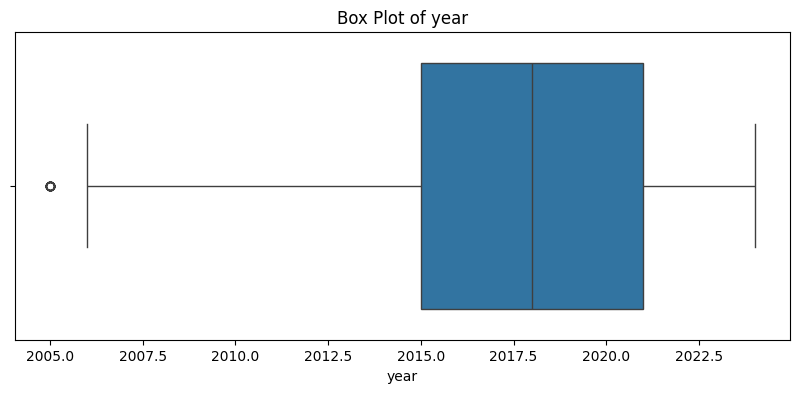

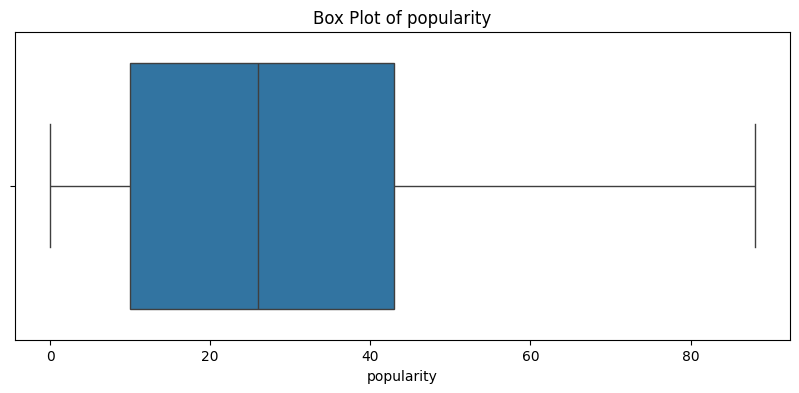

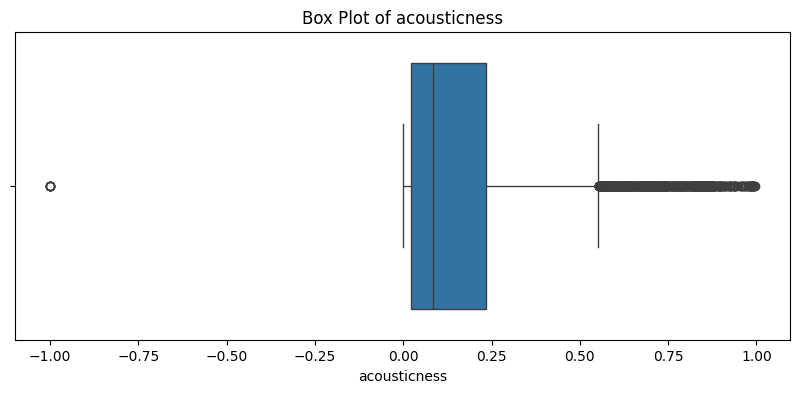

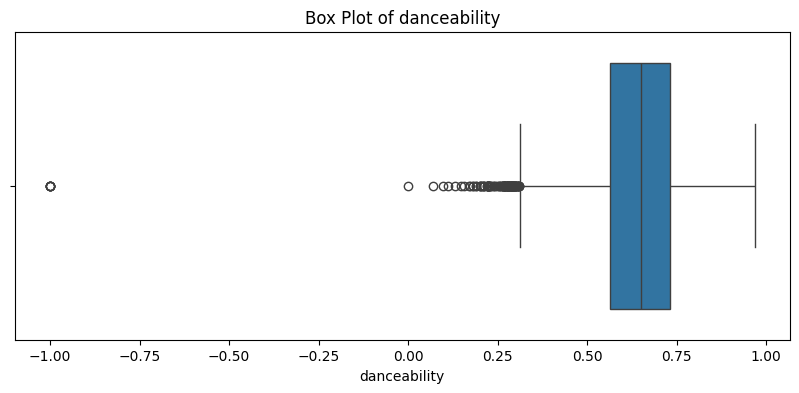

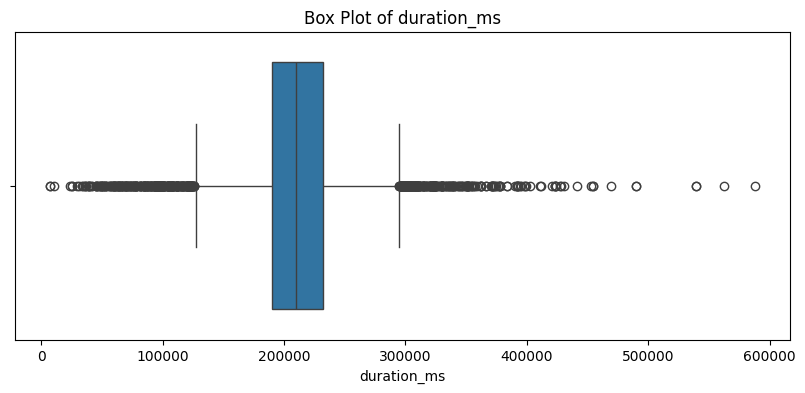

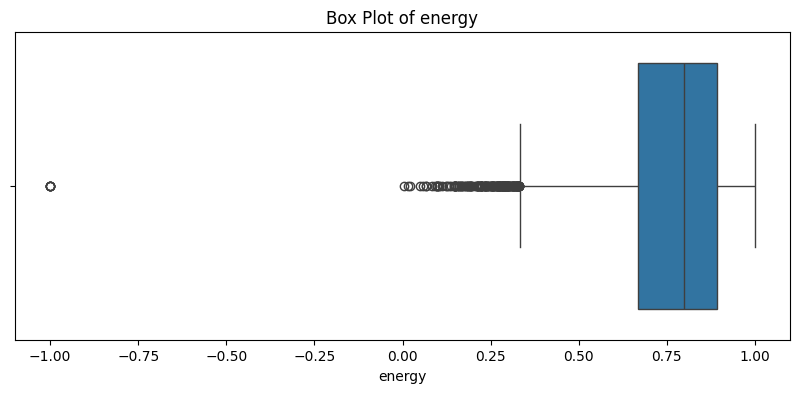

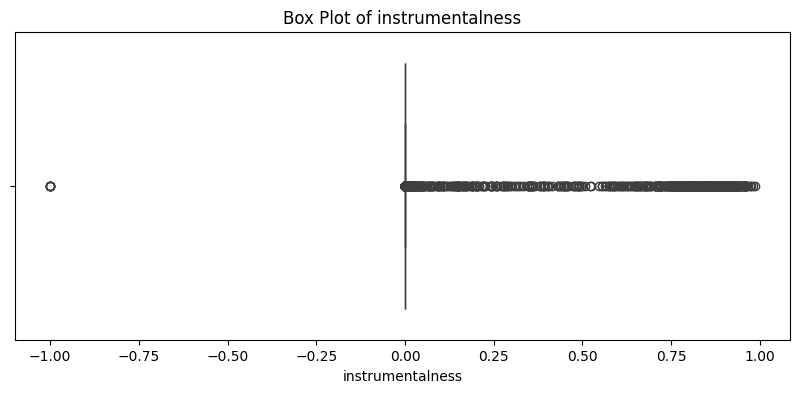

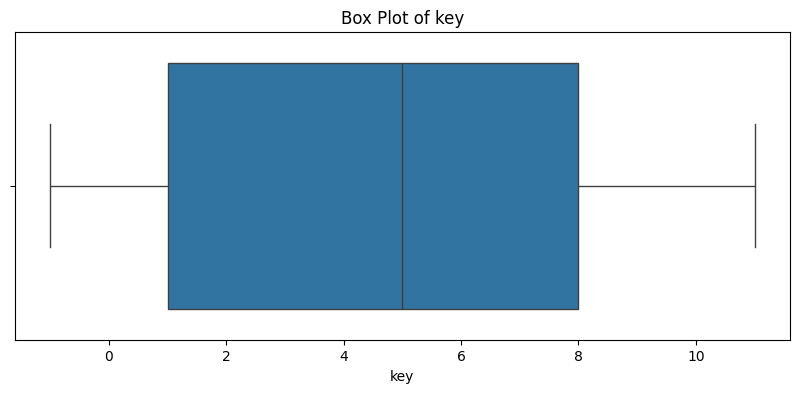

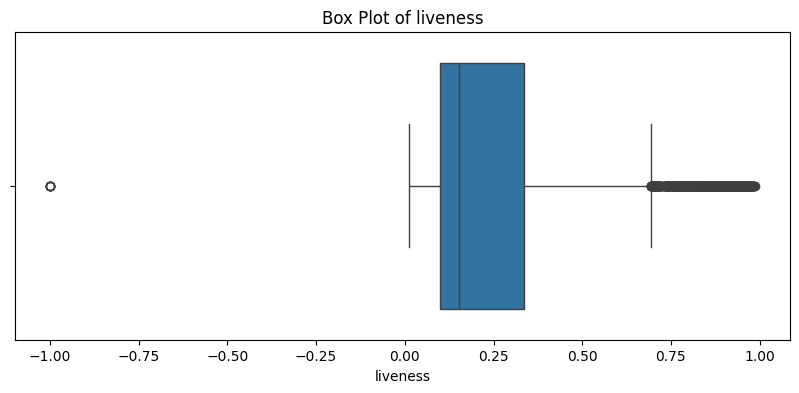

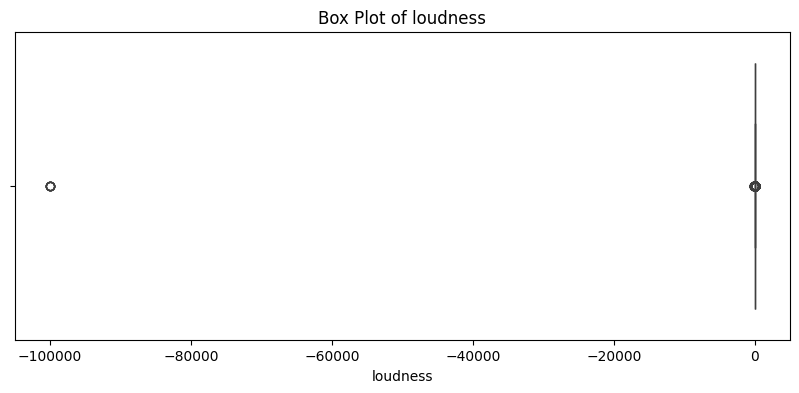

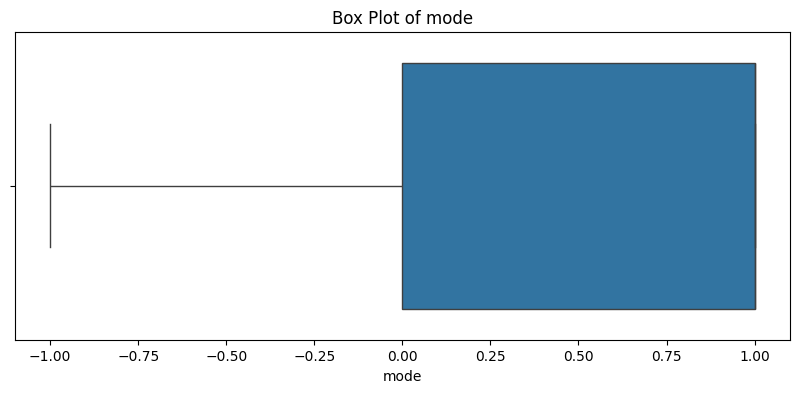

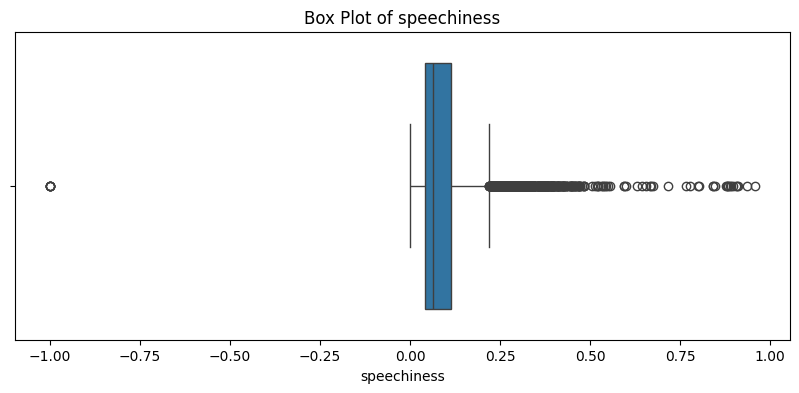

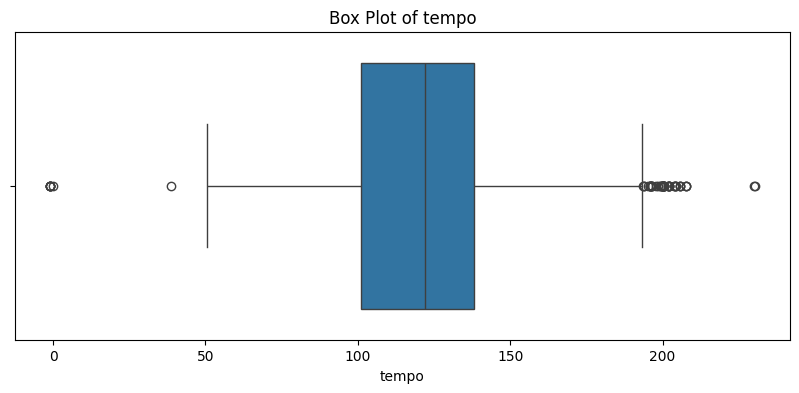

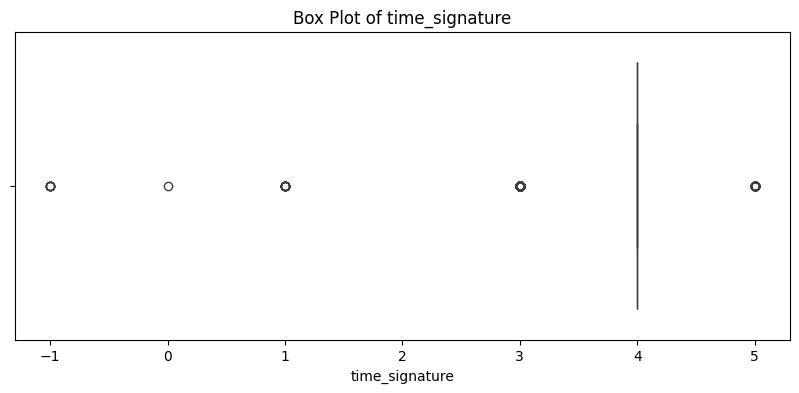

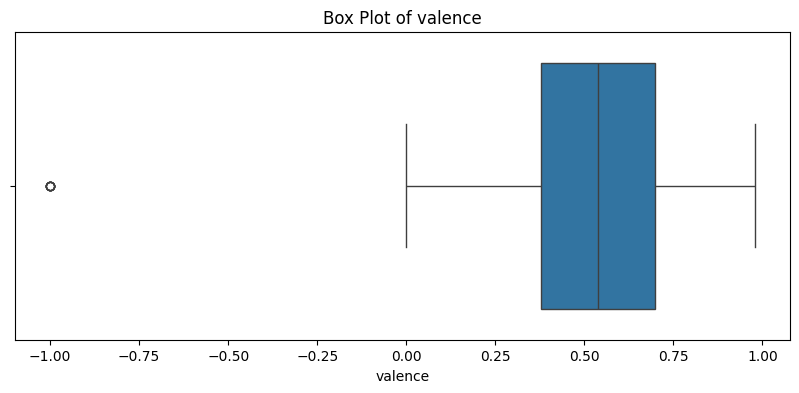

In [47]:
import seaborn as sns
import matplotlib.pyplot as plt

numeric_features = df.select_dtypes(include=["number"]).columns

for feature in numeric_features:
    plt.figure(figsize=(10, 4))
    sns.boxplot(x=df[feature])
    plt.title(f"Box Plot of {feature}")
    plt.show()

In [48]:
# Mengidentifikasi outliers menggunakan IQR
Q1 = df[numeric_features].quantile(0.25)
Q3 = df[numeric_features].quantile(0.75)
IQR = Q3 - Q1

jumlah_outlier = ((df[numeric_features] < (Q1 - 1.5 * IQR)) | (df[numeric_features] > (Q3 + 1.5 * IQR))).sum()
jumlah_outlier

year                  22
popularity             0
acousticness         551
danceability         110
duration_ms          533
energy               192
instrumentalness    1527
key                    0
liveness             537
loudness             388
mode                   0
speechiness          633
tempo                 58
time_signature       245
valence                6
dtype: int64

In [49]:
# Menghapus baris yang mengandung outliers pada kolom numerik
condition = ~((df[numeric_features] < (Q1 - 1.5 * IQR)) | (df[numeric_features] > (Q3 + 1.5 * IQR))).any(axis=1)
df_filtered_numeric = df.loc[condition, numeric_features]

# Menggabungkan kembali dengan kolom kategorikal
categorical_features = df.select_dtypes(exclude=["number"]).columns
df = pd.concat([df_filtered_numeric, df.loc[condition, categorical_features]], axis=1)

print("Jumlah data sebelum penghapusan outlier:", len(train))
print("Jumlah data setelah penghapusan outlier:", len(df))

Jumlah data sebelum penghapusan outlier: 6893
Jumlah data setelah penghapusan outlier: 3847


In [50]:
# Setelah outlier dihapus, kolom yang nilainya sama semua (tidak bervariasi) tidak berguna untuk model
kolom_konstan = [c for c in numeric_features if df[c].nunique() == 1]
print("Kolom konstan:", kolom_konstan)

df = df.drop(columns=kolom_konstan)
numeric_features = df.select_dtypes(include=["number"]).columns
print("Ukuran data:", df.shape)

Kolom konstan: ['time_signature']
Ukuran data: (3847, 15)


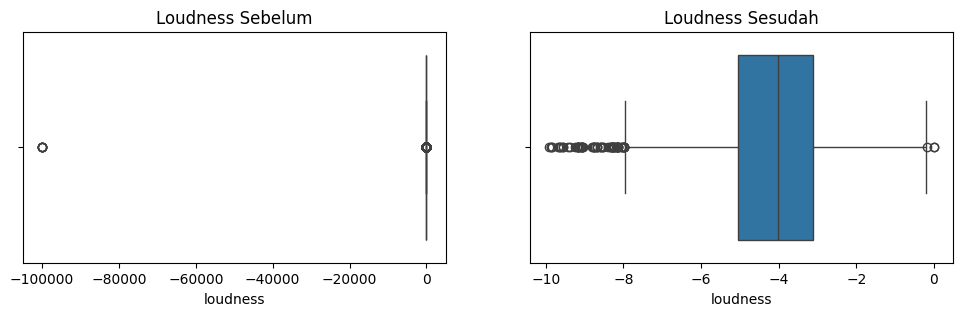

In [51]:
# Perbandingan sebelum dan sesudah penanganan outlier (contoh: loudness)
fig, axes = plt.subplots(1, 2, figsize=(12, 3))
sns.boxplot(x=train["loudness"], ax=axes[0]); axes[0].set_title("Loudness Sebelum")
sns.boxplot(x=df["loudness"], ax=axes[1]); axes[1].set_title("Loudness Sesudah")
plt.show()

## Normalisasi dan Standardisasi Data

In [52]:
from sklearn.preprocessing import StandardScaler

# Menyimpan rata-rata dan standar deviasi asli popularity (untuk menerjemahkan hasil model ke skala 0-100)
pop_mean = df["popularity"].mean()
pop_std = df["popularity"].std(ddof=0)

# Standardisasi fitur numerik
scaler = StandardScaler()
df[numeric_features] = scaler.fit_transform(df[numeric_features])
df[numeric_features].describe().T[["mean", "std"]]

,mean,std
year,-2.166167e-14,1.00013
popularity,1.329843e-16,1.00013
acousticness,4.432811e-17,1.00013
danceability,6.796978e-16,1.00013
duration_ms,2.798212e-16,1.00013
energy,-5.171613e-17,1.00013
instrumentalness,-1.477604e-17,1.00013
key,-6.187466e-17,1.00013
liveness,2.438046e-16,1.00013
loudness,-1.182083e-16,1.00013


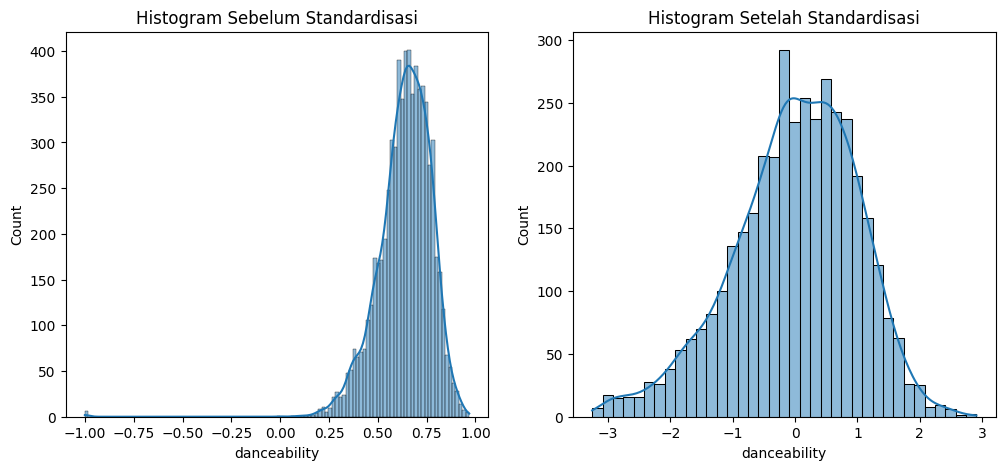

In [53]:
# Histogram Sebelum Standardisasi
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.histplot(train["danceability"], kde=True)
plt.title("Histogram Sebelum Standardisasi")

# Histogram Setelah Standardisasi
plt.subplot(1, 2, 2)
sns.histplot(df["danceability"], kde=True)
plt.title("Histogram Setelah Standardisasi")
plt.show()

## Menangani Duplikasi Data

In [54]:
# Mengidentifikasi baris duplikat
duplicates = df.duplicated()

print("Jumlah baris duplikat:", duplicates.sum())
print(df[duplicates].head())

Jumlah baris duplikat: 52
          year  popularity  acousticness  danceability  duration_ms    energy  \
629   0.788674    0.633300      0.256577     -0.082538     0.074749  0.894089   
731   1.030102   -1.786068      1.199701     -0.728490    -2.349058  1.325581   
735   1.030102   -1.786068     -0.884990     -1.915901    -1.196936  1.040634   
1815  1.512958    1.869865     -0.608469     -1.345944    -1.381718  0.071812   
3330 -2.591321   -1.463486     -0.875945     -2.096388    -0.999411  0.812676   

      instrumentalness       key  liveness  loudness      mode  speechiness  \
629          -0.277703 -1.407761 -0.455489  0.935788 -1.161291    -0.564703   
731          -0.277703  1.639724 -0.371368  0.438344 -1.161291     0.233878   
735           1.351339 -1.130717 -0.462500  0.296312 -1.161291    -0.555830   
1815         -0.277703  0.808591 -0.767440  0.285742  0.861111    -0.482626   
3330          1.555993  1.362680 -0.783563  0.129176 -1.161291     0.056415   

         tem

In [55]:
# Menghapus baris duplikat (jika ada)
df = df.drop_duplicates()
print("Ukuran DataFrame setelah menghapus duplikat:", df.shape)

Ukuran DataFrame setelah menghapus duplikat: (3795, 15)


## Mengonversi Tipe Data

In [56]:
category_features = df.select_dtypes(exclude=["number"]).columns
df[category_features].head()

,artist_name
2,BTS
3,BTS
4,BTS
5,BTS
6,BTS


### One Hot Encoding

In [57]:
df_one_hot = pd.get_dummies(df, columns=category_features)
print("Jumlah kolom sebelum One Hot Encoding:", df.shape[1])
print("Jumlah kolom sesudah One Hot Encoding:", df_one_hot.shape[1])
df_one_hot.head()

Jumlah kolom sebelum One Hot Encoding: 15
Jumlah kolom sesudah One Hot Encoding: 132


,year,popularity,acousticness,danceability,duration_ms,energy,instrumentalness,key,liveness,loudness,...,artist_name_Twice,artist_name_WEi,artist_name_aespa,"artist_name_aespa, Tropkillaz","artist_name_aespa, nævis",artist_name_bibi,artist_name_iKON,"artist_name_iKON, RAE SEONG CHOE",artist_name_iKon,artist_name_wei
2,1.271530,2.299975,-0.749938,-0.424512,0.695083,-1.686721,-0.277703,0.531547,1.226941,-1.215179,...,False,False,False,False,False,False,False,False,False,False
3,1.271530,1.708574,-0.953390,0.031454,-1.201697,0.421890,-0.277703,-1.407761,-0.020861,0.343215,...,False,False,False,False,False,False,False,False,False,False
4,1.030102,2.407503,-0.801732,0.591912,-0.220881,0.177650,-0.277703,0.808591,-1.171924,0.258657,...,False,False,False,False,False,False,False,False,False,False
5,1.030102,2.299975,-0.932146,0.924387,-1.685220,-2.745098,-0.277703,0.808591,-0.870489,-0.692631,...,False,False,False,False,False,False,False,False,False,False
6,1.030102,2.031157,-0.623157,-0.975471,-0.636365,0.723121,-0.277703,-1.130717,0.911486,-0.248697,...,False,False,False,False,False,False,False,False,False,False


### Label Encoding
Label Encoding dipakai karena One Hot Encoding membuat jumlah kolom membengkak (nama artis sangat banyak), sedangkan Label Encoding tidak menambah kolom.

In [58]:
from sklearn.preprocessing import LabelEncoder

# Inisialisasi LabelEncoder
label_encoder = LabelEncoder()
df_lencoder = pd.DataFrame(df)

for col in category_features:
    df_lencoder[col] = label_encoder.fit_transform(df[col])

# Menampilkan hasil
df_lencoder.head()

,year,popularity,acousticness,danceability,duration_ms,energy,instrumentalness,key,liveness,loudness,mode,speechiness,tempo,valence,artist_name
2,1.271530,2.299975,-0.749938,-0.424512,0.695083,-1.686721,-0.277703,0.531547,1.226941,-1.215179,0.861111,-0.939592,-1.121078,-0.057582,29
3,1.271530,1.708574,-0.953390,0.031454,-1.201697,0.421890,-0.277703,-1.407761,-0.020861,0.343215,0.861111,-0.134357,-0.016951,0.555632,29
4,1.030102,2.407503,-0.801732,0.591912,-0.220881,0.177650,-0.277703,0.808591,-1.171924,0.258657,0.861111,2.021810,-1.774965,0.601243,29
5,1.030102,2.299975,-0.932146,0.924387,-1.685220,-2.745098,-0.277703,0.808591,-0.870489,-0.692631,0.861111,0.398030,-0.425513,0.596175,29
6,1.030102,2.031157,-0.623157,-0.975471,-0.636365,0.723121,-0.277703,-1.130717,0.911486,-0.248697,0.861111,2.487649,2.111669,0.535360,29


# 4. EDA (Exploratory Data Analysis)

In [59]:
df_lencoder.head()

,year,popularity,acousticness,danceability,duration_ms,energy,instrumentalness,key,liveness,loudness,mode,speechiness,tempo,valence,artist_name
2,1.271530,2.299975,-0.749938,-0.424512,0.695083,-1.686721,-0.277703,0.531547,1.226941,-1.215179,0.861111,-0.939592,-1.121078,-0.057582,29
3,1.271530,1.708574,-0.953390,0.031454,-1.201697,0.421890,-0.277703,-1.407761,-0.020861,0.343215,0.861111,-0.134357,-0.016951,0.555632,29
4,1.030102,2.407503,-0.801732,0.591912,-0.220881,0.177650,-0.277703,0.808591,-1.171924,0.258657,0.861111,2.021810,-1.774965,0.601243,29
5,1.030102,2.299975,-0.932146,0.924387,-1.685220,-2.745098,-0.277703,0.808591,-0.870489,-0.692631,0.861111,0.398030,-0.425513,0.596175,29
6,1.030102,2.031157,-0.623157,-0.975471,-0.636365,0.723121,-0.277703,-1.130717,0.911486,-0.248697,0.861111,2.487649,2.111669,0.535360,29


In [60]:
# Menghitung jumlah dan persentase missing values di setiap kolom
missing_values = df_lencoder.isnull().sum()
missing_percentage = (missing_values / len(df_lencoder)) * 100

missing_data = pd.DataFrame({
    "Missing Values": missing_values,
    "Percentage": missing_percentage
}).sort_values(by="Missing Values", ascending=False)

print("Kolom dengan missing value:", (missing_data["Missing Values"] > 0).sum())
missing_data[missing_data["Missing Values"] > 0]

Kolom dengan missing value: 0


,Missing Values,Percentage


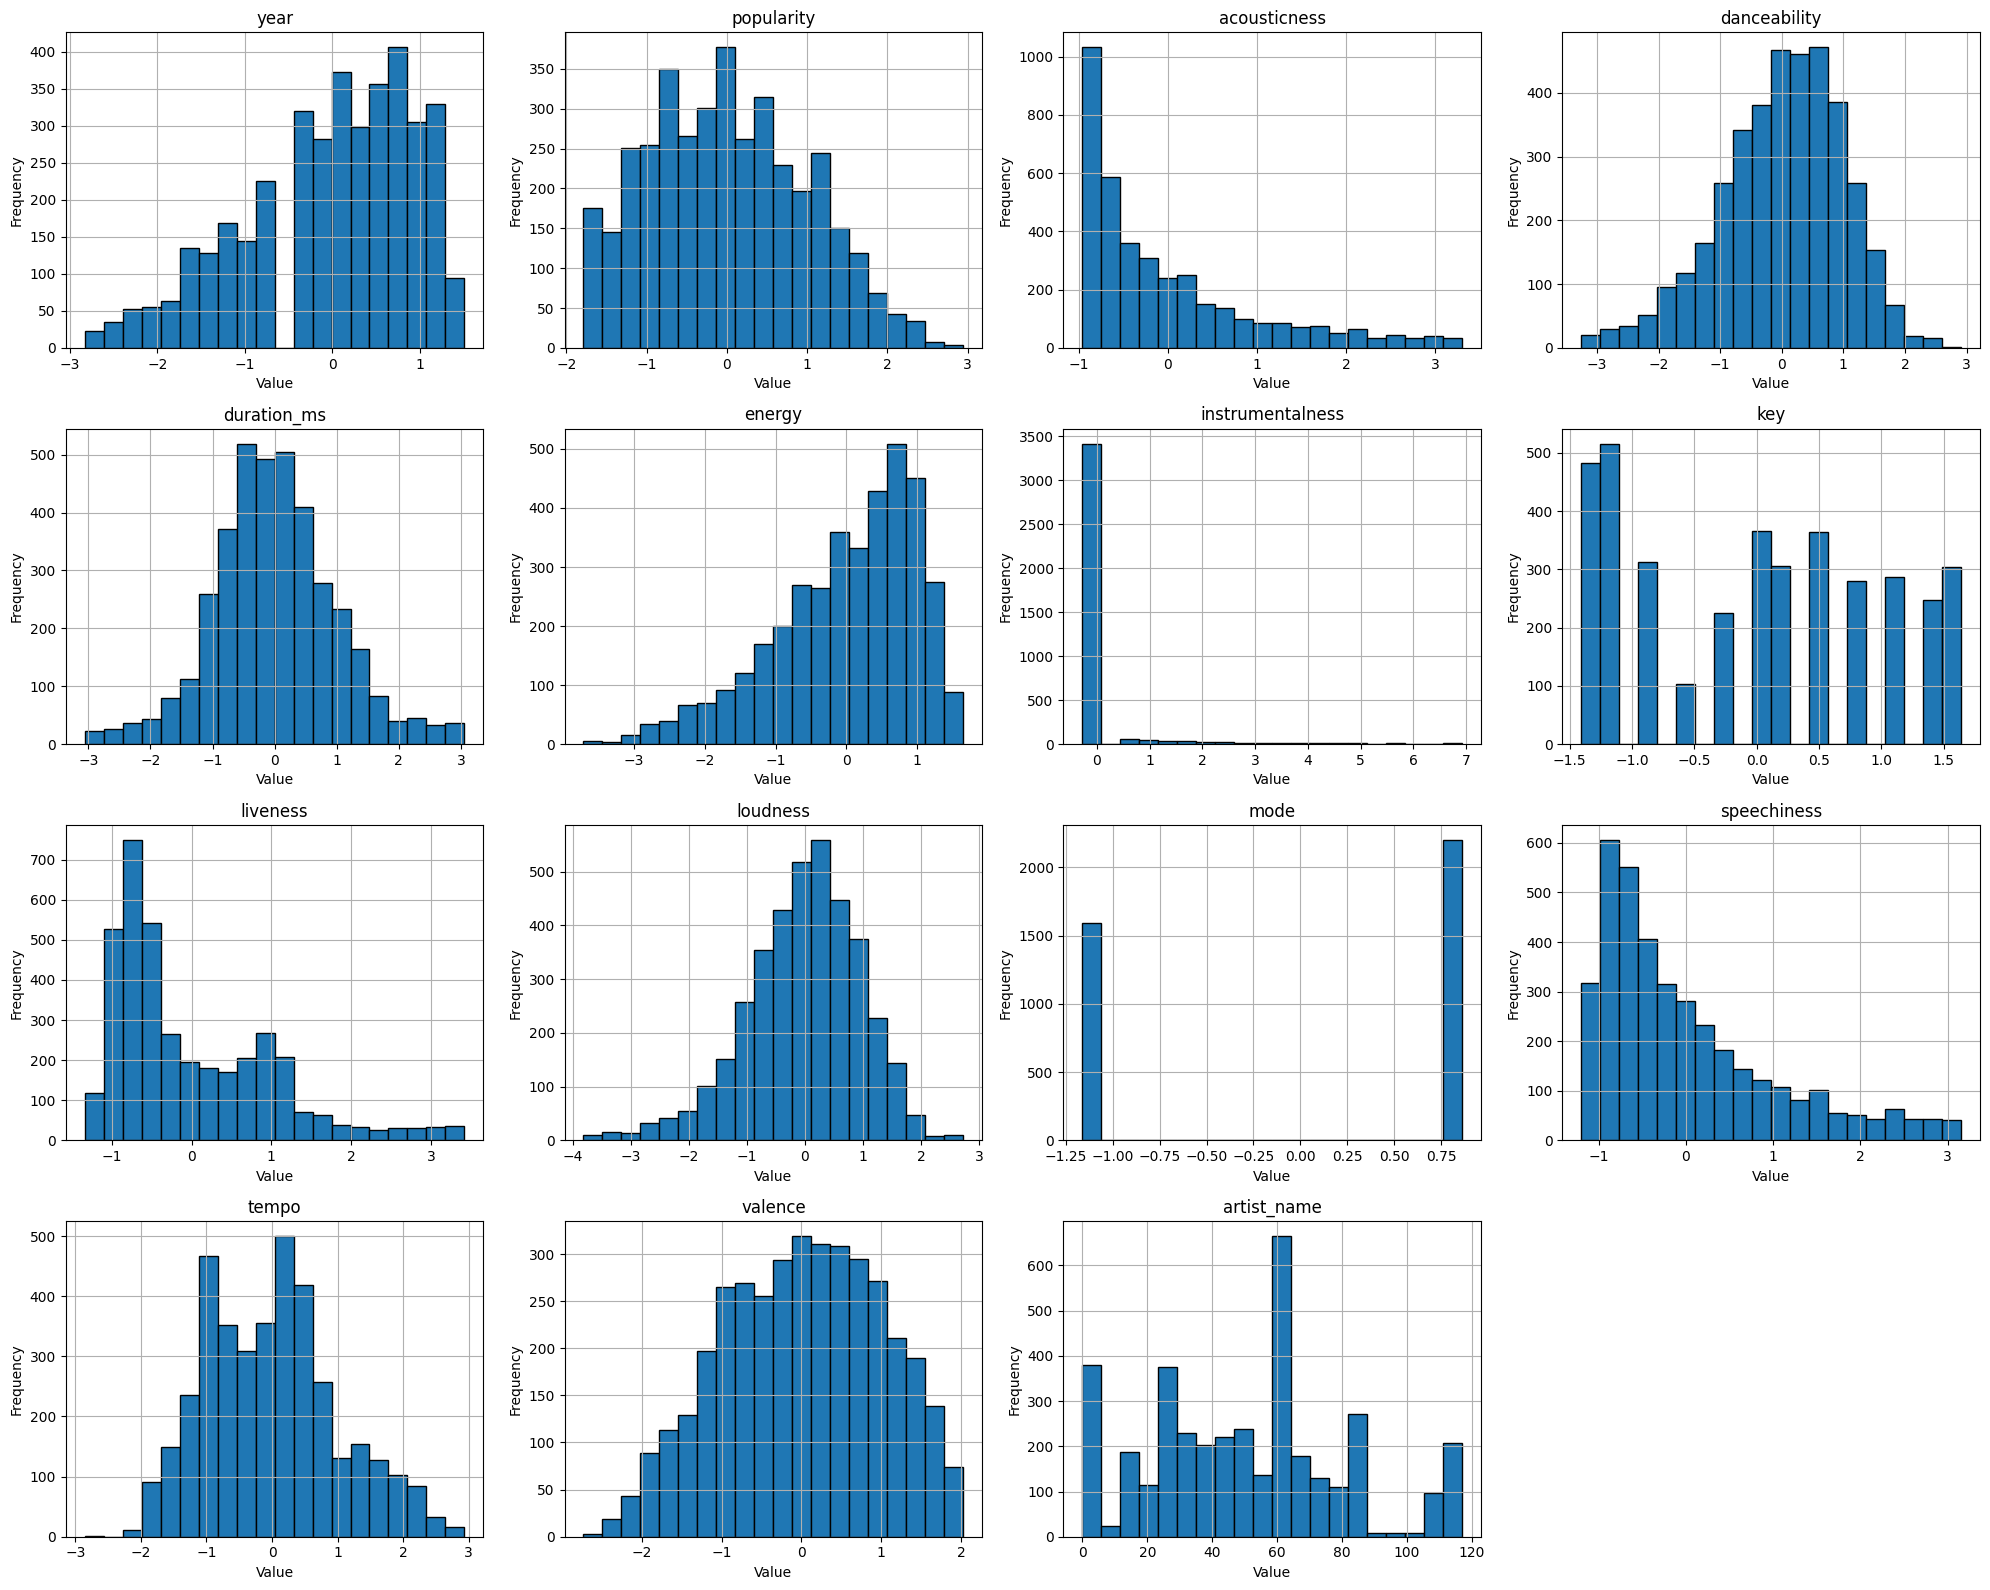

In [61]:
# Menghitung jumlah variabel
num_vars = df_lencoder.shape[1]

# Menentukan jumlah baris dan kolom untuk grid subplot
n_cols = 4
n_rows = -(-num_vars // n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, n_rows * 4))
axes = axes.flatten()

for i, column in enumerate(df_lencoder.columns):
    df_lencoder[column].hist(ax=axes[i], bins=20, edgecolor="black")
    axes[i].set_title(column)
    axes[i].set_xlabel("Value")
    axes[i].set_ylabel("Frequency")

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

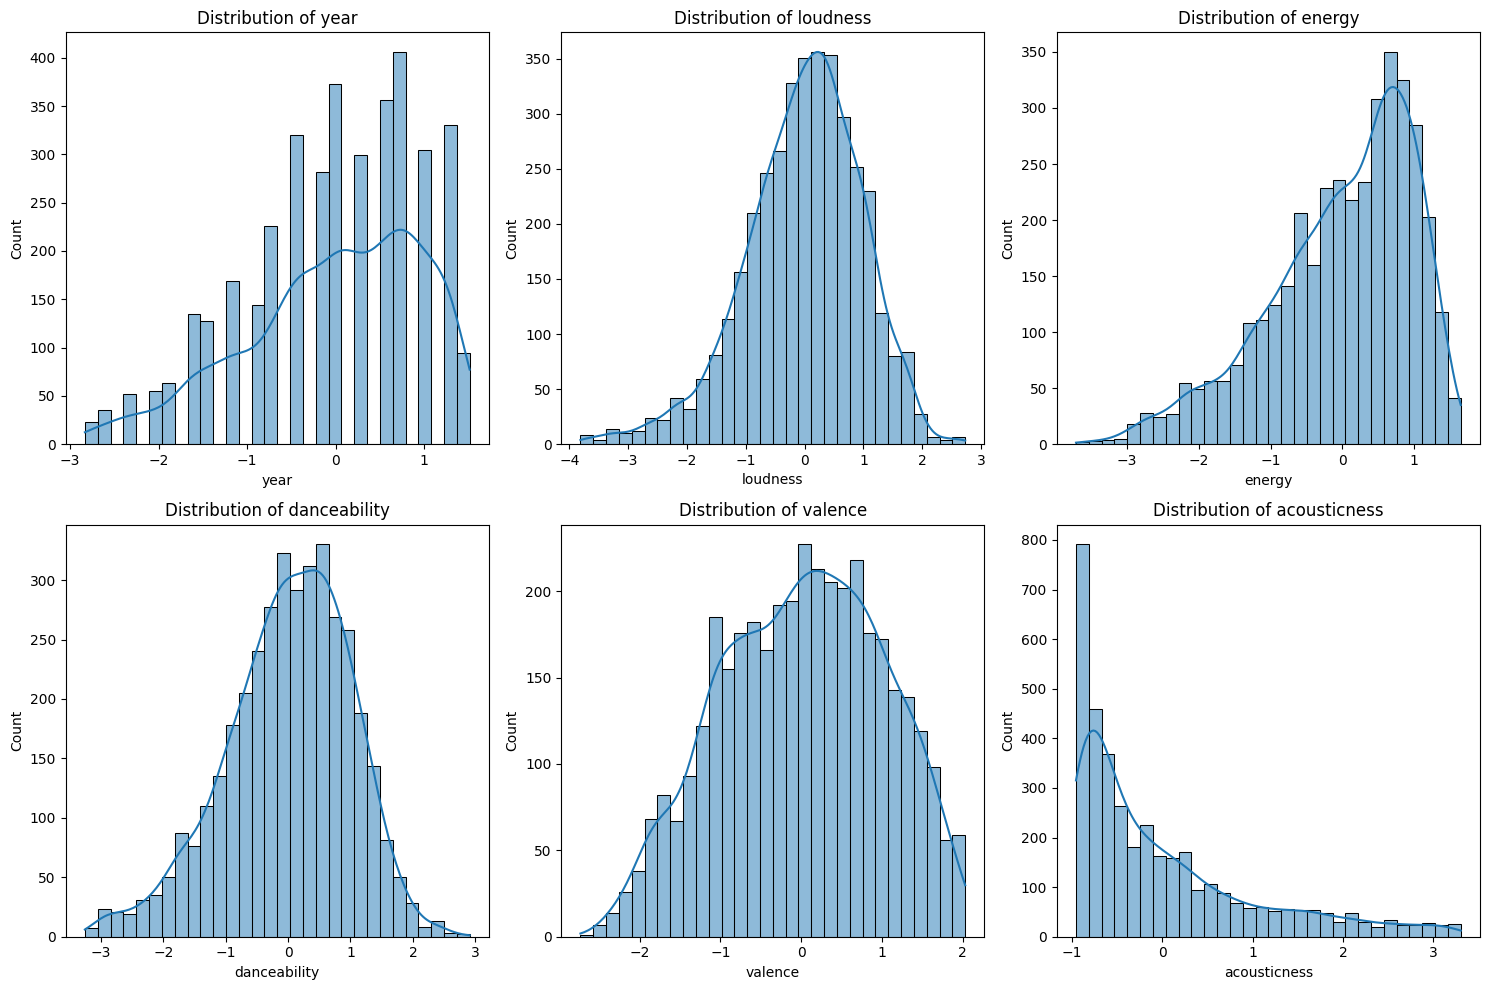

In [62]:
# Visualisasi distribusi data untuk beberapa kolom
columns_to_plot = ["year", "loudness", "energy", "danceability", "valence", "acousticness"]

plt.figure(figsize=(15, 10))
for i, column in enumerate(columns_to_plot, 1):
    plt.subplot(2, 3, i)
    sns.histplot(df_lencoder[column], kde=True, bins=30)
    plt.title(f"Distribution of {column}")

plt.tight_layout()
plt.show()

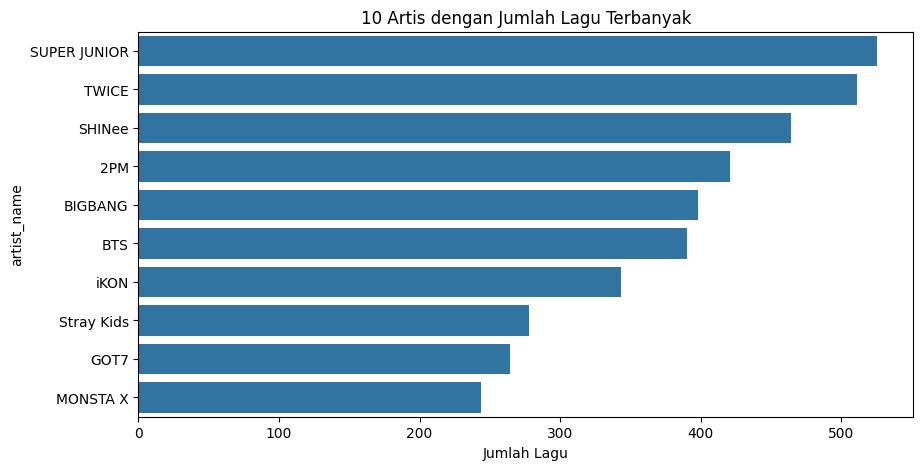

In [63]:
# 10 artis dengan jumlah lagu terbanyak (dari data K-Pop awal)
top_artis = train["artist_name"].value_counts().head(10)
plt.figure(figsize=(10, 5))
sns.barplot(x=top_artis.values, y=top_artis.index)
plt.title("10 Artis dengan Jumlah Lagu Terbanyak")
plt.xlabel("Jumlah Lagu")
plt.show()

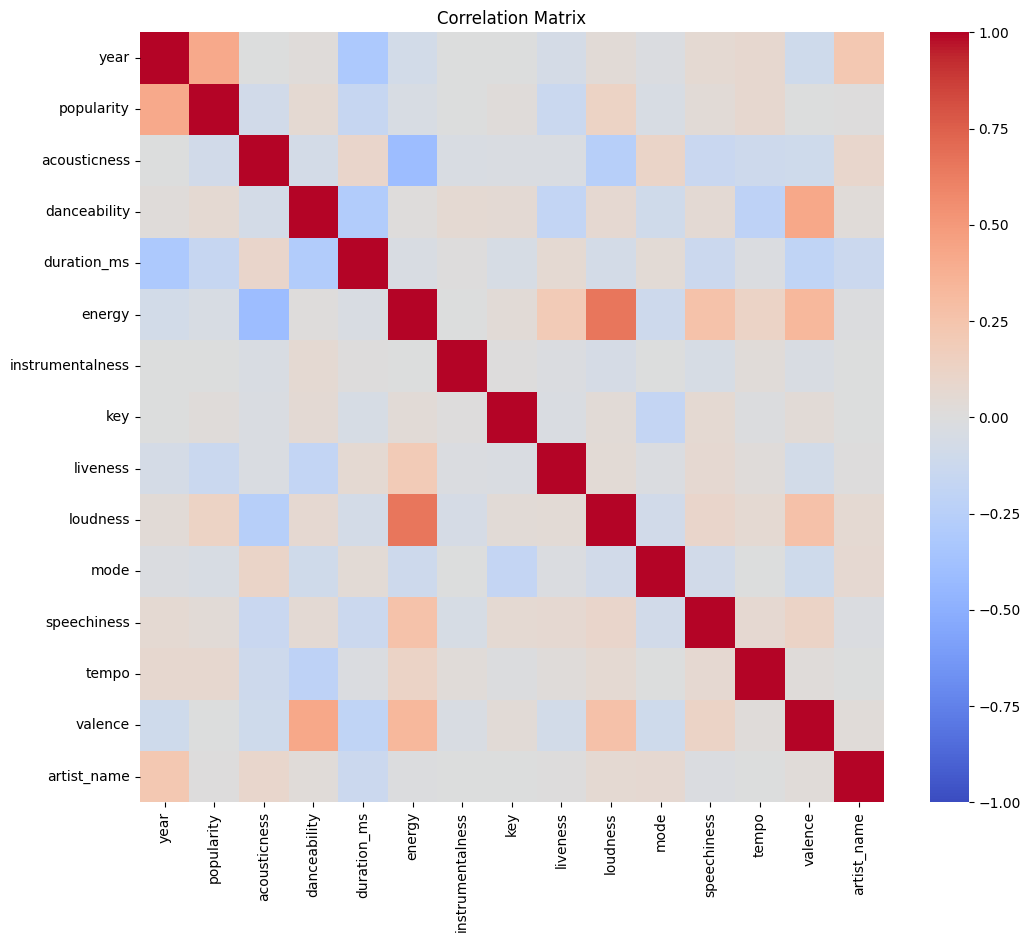

In [64]:
# Visualisasi korelasi antar variabel numerik
plt.figure(figsize=(12, 10))
correlation_matrix = df_lencoder.corr()

sns.heatmap(correlation_matrix, annot=False, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Matrix")
plt.show()

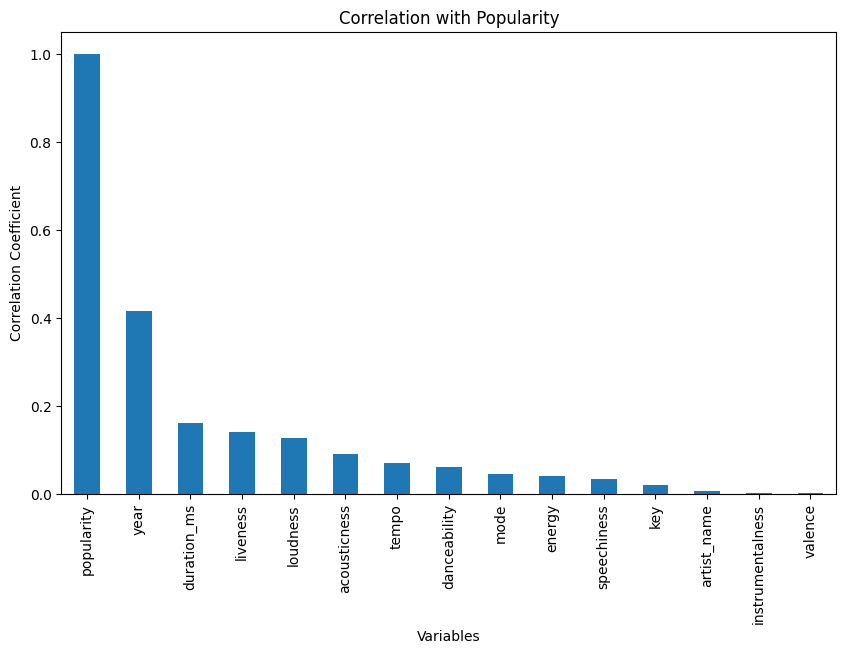

year                0.414800
loudness            0.127744
tempo               0.070713
danceability        0.060246
speechiness         0.034465
key                 0.020772
artist_name         0.005166
valence            -0.001291
instrumentalness   -0.002086
energy             -0.041027
mode               -0.044222
acousticness       -0.090183
liveness           -0.139905
duration_ms        -0.160203
Name: popularity, dtype: float64

In [65]:
# Menghitung korelasi antara variabel target dan semua variabel lainnya
target_corr = df_lencoder.corr()["popularity"]

# Mengurutkan hasil korelasi berdasarkan korelasi
target_corr_sorted = target_corr.abs().sort_values(ascending=False)

plt.figure(figsize=(10, 6))
target_corr_sorted.plot(kind="bar")
plt.title("Correlation with Popularity")
plt.xlabel("Variables")
plt.ylabel("Correlation Coefficient")
plt.show()

target_corr.drop("popularity").sort_values(ascending=False)

# 5. DATA SPLITTING

In [66]:
import sklearn

In [79]:
# Memisahkan fitur (X) dan target (y)
X = df_lencoder.drop(columns=["popularity"])
y = df_lencoder["popularity"]

In [80]:
from sklearn.model_selection import train_test_split

# Membagi dataset menjadi data latih (80%) dan data uji (20%)
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)

In [69]:

print("Jumlah data       :", len(X))
print("Jumlah data latih :", len(x_train))
print("Jumlah data uji   :", len(x_test))

Jumlah data       : 3795
Jumlah data latih : 3036
Jumlah data uji   : 759


# 6. MODELLING

In [70]:
# Melatih model 1 dengan algoritma Least Angle Regression
from sklearn import linear_model
lars = linear_model.Lars(n_nonzero_coefs=1).fit(x_train, y_train)

# Melatih model 2 dengan algoritma Linear Regression
from sklearn.linear_model import LinearRegression
LR = LinearRegression().fit(x_train, y_train)

# Melatih model 3 dengan algoritma Gradient Boosting Regressor
from sklearn.ensemble import GradientBoostingRegressor
GBR = GradientBoostingRegressor(random_state=184)
GBR.fit(x_train, y_train)

,"loss loss: {'squared_error', 'absolute_error', 'huber', 'quantile'}, default='squared_error'Loss function to be optimized. 'squared_error' refers to the squarederror for regression. 'absolute_error' refers to the absolute error ofregression and is a robust loss function. 'huber' is acombination of the two. 'quantile' allows quantile regression (use`alpha` to specify the quantile).See:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_quantile.py`for an example that demonstrates quantile regression for creatingprediction intervals with `loss='quantile'`.",'squared_error'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'The function to measure the quality of a split. Supported criteria are""friedman_mse"" for the mean squared error with improvement score byFriedman, ""squared_error"" for mean squared error. The default value of""friedman_mse"" is generally the best as it can provide a betterapproximation in some cases... versionadded:: 0.18",'friedman_mse'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft 

In [71]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Evaluasi pada model LARS
pred_lars = lars.predict(x_test)
mae_lars = mean_absolute_error(y_test, pred_lars)
mse_lars = mean_squared_error(y_test, pred_lars)
r2_lars = r2_score(y_test, pred_lars)

# Membuat dictionary untuk menyimpan hasil evaluasi
data_hasil = {
    "MAE": [mae_lars],
    "MSE": [mse_lars],
    "R2": [r2_lars]
}

# Konversi dictionary menjadi DataFrame
df_results = pd.DataFrame(data_hasil, index=["Lars"])
df_results

,MAE,MSE,R2
Lars,0.778738,0.90585,0.068271


In [72]:
# Evaluasi pada model Linear Regression
pred_LR = LR.predict(x_test)
mae_LR = mean_absolute_error(y_test, pred_LR)
mse_LR = mean_squared_error(y_test, pred_LR)
r2_LR = r2_score(y_test, pred_LR)

# Menambahkan hasil evaluasi LR ke DataFrame
df_results.loc["Linear Regression"] = [mae_LR, mse_LR, r2_LR]
df_results

,MAE,MSE,R2
Lars,0.778738,0.90585,0.068271
Linear Regression,0.689059,0.77458,0.203292


In [73]:
# Evaluasi pada model Gradient Boosting Regressor
pred_GBR = GBR.predict(x_test)
mae_GBR = mean_absolute_error(y_test, pred_GBR)
mse_GBR = mean_squared_error(y_test, pred_GBR)
r2_GBR = r2_score(y_test, pred_GBR)

# Menambahkan hasil evaluasi GBR ke DataFrame
df_results.loc["GradientBoostingRegressor"] = [mae_GBR, mse_GBR, r2_GBR]
df_results

,MAE,MSE,R2
Lars,0.778738,0.905850,0.068271
Linear Regression,0.689059,0.774580,0.203292
GradientBoostingRegressor,0.525349,0.448794,0.538385


Catatan: karena `popularity` ikut distandardisasi, nilai MAE di atas dalam satuan standar deviasi. Sel berikut menerjemahkannya kembali ke skala popularity asli (0-100).

In [74]:
# Rata-rata kesalahan prediksi dalam poin popularity asli
df_results["MAE (poin popularity)"] = df_results["MAE"] * pop_std
df_results

,MAE,MSE,R2,MAE (poin popularity)
Lars,0.778738,0.905850,0.068271,14.484447
Linear Regression,0.689059,0.774580,0.203292,12.816419
GradientBoostingRegressor,0.525349,0.448794,0.538385,9.771439


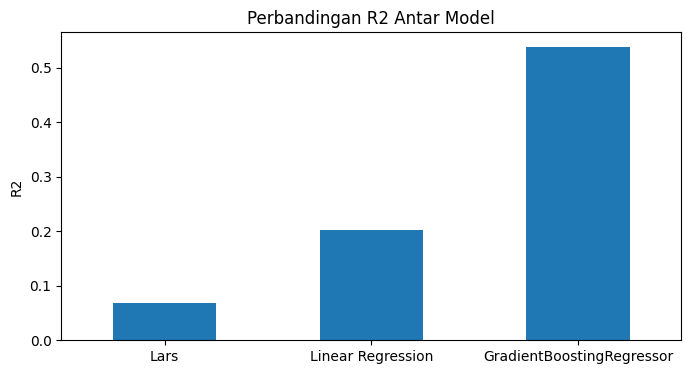

In [75]:
# Perbandingan nilai R2 antar model (makin tinggi makin baik)
df_results["R2"].plot(kind="bar", figsize=(8, 4))
plt.title("Perbandingan R2 Antar Model")
plt.ylabel("R2")
plt.xticks(rotation=0)
plt.show()

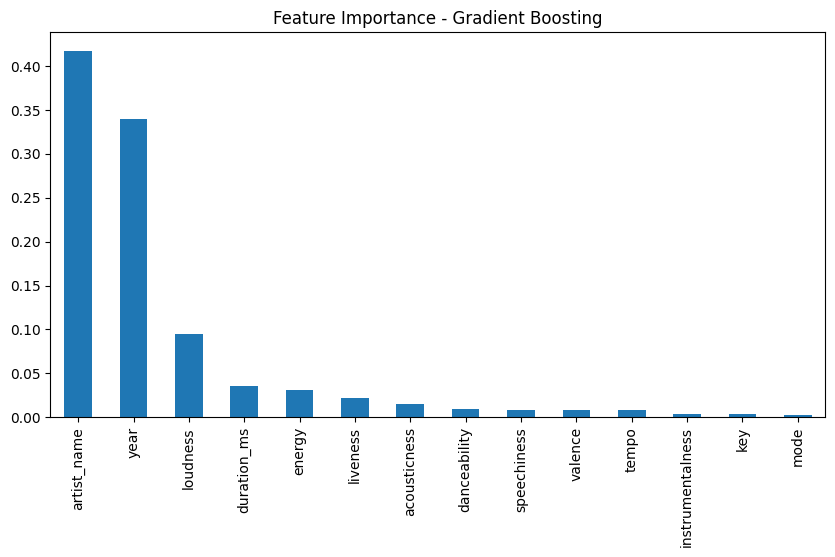

artist_name         0.417620
year                0.339307
loudness            0.094326
duration_ms         0.035964
energy              0.030945
liveness            0.022219
acousticness        0.015051
danceability        0.009868
speechiness         0.008582
valence             0.008241
tempo               0.007720
instrumentalness    0.004120
key                 0.003347
mode                0.002689
dtype: float64

In [76]:
# Fitur yang paling berpengaruh menurut Gradient Boosting
importance = pd.Series(GBR.feature_importances_, index=x_train.columns).sort_values(ascending=False)
importance.plot(kind="bar", figsize=(10, 5))
plt.title("Feature Importance - Gradient Boosting")
plt.show()
importance

## Menyimpan Model

In [77]:
import joblib

# Menyimpan model ke dalam file
joblib.dump(GBR, "gbr_model.joblib")

['gbr_model.joblib']

In [78]:
import pickle

# Menyimpan model dengan pickle
with open("gbr_model.pkl", "wb") as file:
    pickle.dump(GBR, file)

# 7. DEPLOYMENT

Pada bagian ini, model Gradient Boosting yang sudah disimpan akan dicoba melalui API sederhana menggunakan Flask. API menerima data fitur lagu dan mengembalikan hasil prediksi popularity.


## Memuat Model
Model disimpan dalam dua format, yaitu `joblib` dan `pickle`. Pada API, file `gbr_model.joblib` digunakan untuk membuat prediksi. Kode berikut juga memuat model dari file pickle sesuai materi.


In [ ]:
import joblib
import pickle

# Memuat model dari file joblib
joblib_model = joblib.load('gbr_model.joblib')

# Memuat model dari file pickle
with open('gbr_model.pkl', 'rb') as file:
    pickle_model = pickle.load(file)

print('Model joblib dan pickle berhasil dimuat')


## Menjalankan API
Kode API ada di file `testing_deploy.py`. Jalankan file tersebut dari terminal VS Code. Kalau berhasil, Flask akan berjalan di alamat lokal.


## Menguji API
File `data.json` berisi satu contoh data fitur yang formatnya disesuaikan dengan model ini. Saat API sedang berjalan, buka terminal kedua dan jalankan perintah berikut:

```bash
curl -X POST http://127.0.0.1:5000/predict -H "Content-Type: application/json" -d @data.json
```


# 8. MONITORING

Monitoring dilakukan untuk melihat apakah API masih berjalan dan berapa lama model memberikan prediksi. Pada project ini, monitoring dilakukan secara sederhana melalui terminal ketika API menerima permintaan.

Metrik yang diperhatikan:
- **Latency:** waktu yang dibutuhkan API untuk memberikan prediksi.
- **Error:** pesan kesalahan yang muncul ketika permintaan tidak bisa diproses.
- **MSE dan R-squared (R2):** metrik evaluasi model regresi yang sudah dihitung pada bagian evaluasi sebelumnya.
- **Data drift:** perubahan distribusi data lagu yang masuk dibandingkan dengan data saat model dilatih. Pada latihan ini, data drift belum dibuat sebagai pemantauan otomatis.

Alat seperti Prometheus/Grafana, ELK Stack, Sentry, dan MLflow dapat digunakan pada sistem yang lebih lengkap. Untuk latihan ini, alat-alat tersebut belum dipasang karena monitoring masih dilakukan secara sederhana di local.

Dengan begitu, model sudah dicoba melalui API lokal dan pemantauan dasar dapat dilakukan dari waktu prediksi serta error yang tercatat. Monitoring ini belum sama dengan monitoring otomatis di lingkungan produksi.
